In [5]:
import os, re, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- must match the C++ run you are analysing -----------------------
tau_B      = 20.0
H0x_amp    = 1.73
phi_p      = 0.2

# A2/A3: any run folder (sparse snapshots are fine)
SPARSE_CSV = "output_morphology/output_xi0_5.000000_wtB_1.500000/output_t_3032.csv"
# A1/A4: the DENSE run folder (within-period snapshots)
DENSE_BASE = "output_morphology/output_xi0_5.000000_wtB_1.500000"
WTB        = 1.5                      # omega*tau_B of these runs
omega      = WTB / tau_B

def to_grid(df, col):
    nX, nY = df.i.max()+1, df.j.max()+1
    A = np.full((nX, nY), np.nan)
    A[df.i.values, df.j.values] = df[col].values
    return A                           # A[i,j]: x index i, y index j

def load_snapshot(path):
    df = pd.read_csv(path, skipinitialspace=True)
    g  = {c: to_grid(df, c) for c in ["Mx","My","Hx","Hy","ux","uy","phi"]}
    g["nX"], g["nY"] = df.i.max()+1, df.j.max()+1
    return g

def dense_series(base):
    """every within-period CSV, sorted by iter."""
    paths = sorted(glob.glob(os.path.join(base, "output_t_*.csv")),
                   key=lambda p: int(re.search(r"_(\d+)\.csv", p).group(1)))
    its = np.array([int(re.search(r"_(\d+)\.csv", p).group(1)) for p in paths])
    return its, paths

def wrap_deg(a):                        # wrap angle to (-180,180]
    return np.degrees(np.angle(np.exp(1j*np.radians(a))))

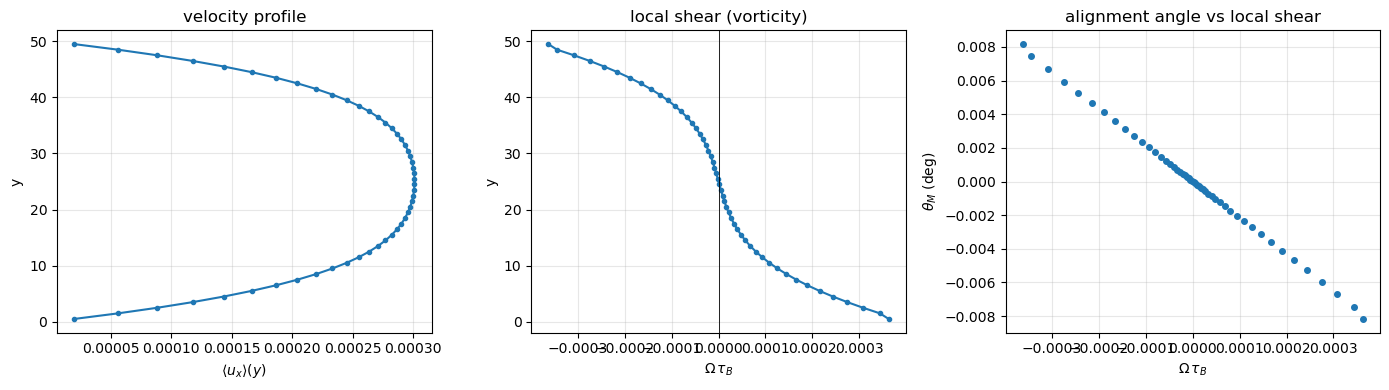

theta_M varies across channel by 0.0163 deg
local Omega*tau_B spans -3.63e-04 .. +3.63e-04


In [6]:
# A2 -- does particle alignment vary with local shear across the channel?
# theta_M measured relative to the applied-field axis (x), averaged over x.
# Omega(y) = 0.5 d<ux>/dy is the local vorticity the particles feel.
g = load_snapshot(SPARSE_CSV)
nX, nY = g["nX"], g["nY"]
Mx, My, ux = g["Mx"], g["My"], g["ux"]

thetaM_y = np.degrees(np.arctan2(My.mean(0), Mx.mean(0)))   # per-y, x-averaged
ux_y     = ux.mean(0)
y        = np.arange(nY) + 0.5
Omega_y  = 0.5 * np.gradient(ux_y, 1.0)                      # local vorticity
OmtB_y   = Omega_y * tau_B

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(ux_y, y, '-o', ms=3); ax[0].set(xlabel=r"$\langle u_x\rangle(y)$", ylabel="y", title="velocity profile")
ax[1].plot(OmtB_y, y, '-o', ms=3); ax[1].axvline(0, c='k', lw=.6); ax[1].set(xlabel=r"$\Omega\,\tau_B$", ylabel="y", title="local shear (vorticity)")
ax[2].plot(OmtB_y, thetaM_y, 'o', ms=4); ax[2].set(xlabel=r"$\Omega\,\tau_B$", ylabel=r"$\theta_M$ (deg)", title="alignment angle vs local shear")
for a in ax: a.grid(alpha=.3)
fig.tight_layout(); plt.show()

print(f"theta_M varies across channel by {thetaM_y.max()-thetaM_y.min():.4f} deg")
print(f"local Omega*tau_B spans {OmtB_y.min():+.2e} .. {OmtB_y.max():+.2e}")

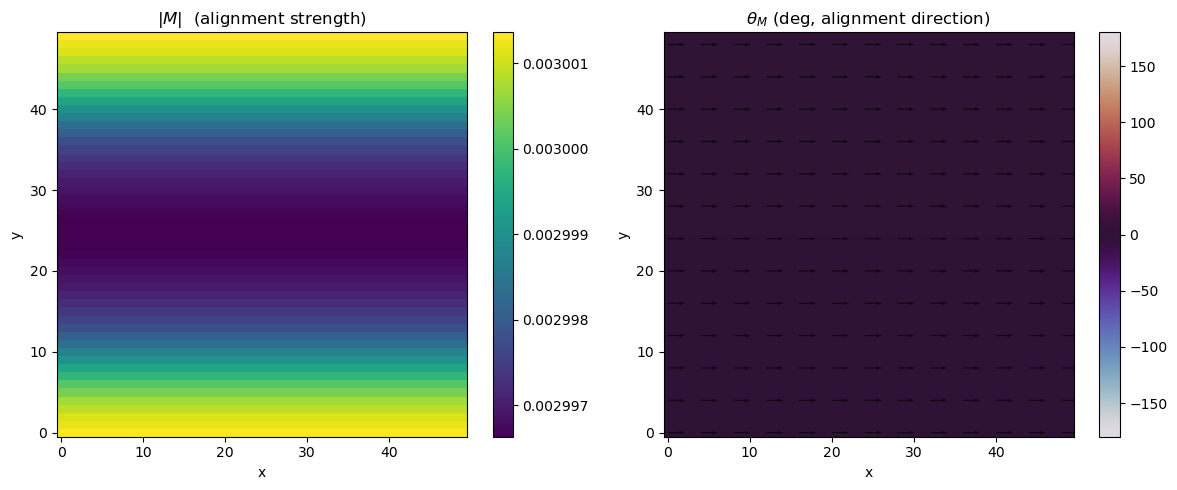

|M|: 2.9966e-03 .. 3.0014e-03   (spread 0.158%)


In [7]:
# A3 -- full 2D maps: how aligned (|M|) and in which direction (theta_M).
g = load_snapshot(SPARSE_CSV)
Mx, My = g["Mx"], g["My"]
Mmag   = np.hypot(Mx, My)
thetaM = np.degrees(np.arctan2(My, Mx))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
im0 = ax[0].imshow(Mmag.T, origin="lower", aspect="auto", cmap="viridis")
ax[0].set(title=r"$|M|$  (alignment strength)", xlabel="x", ylabel="y"); fig.colorbar(im0, ax=ax[0])
im1 = ax[1].imshow(thetaM.T, origin="lower", aspect="auto", cmap="twilight", vmin=-180, vmax=180)
ax[1].set(title=r"$\theta_M$ (deg, alignment direction)", xlabel="x", ylabel="y"); fig.colorbar(im1, ax=ax[1])
# overlay M direction as a quiver (subsampled)
s = 4
X, Y = np.meshgrid(np.arange(g["nX"]), np.arange(g["nY"]))
ax[1].quiver(X[::s,::s], Y[::s,::s], Mx.T[::s,::s], My.T[::s,::s],
             color="k", scale=None, width=.003, alpha=.6)
fig.tight_layout(); plt.show()

print(f"|M|: {Mmag.min():.4e} .. {Mmag.max():.4e}   (spread {100*(Mmag.max()/Mmag.min()-1):.3f}%)")

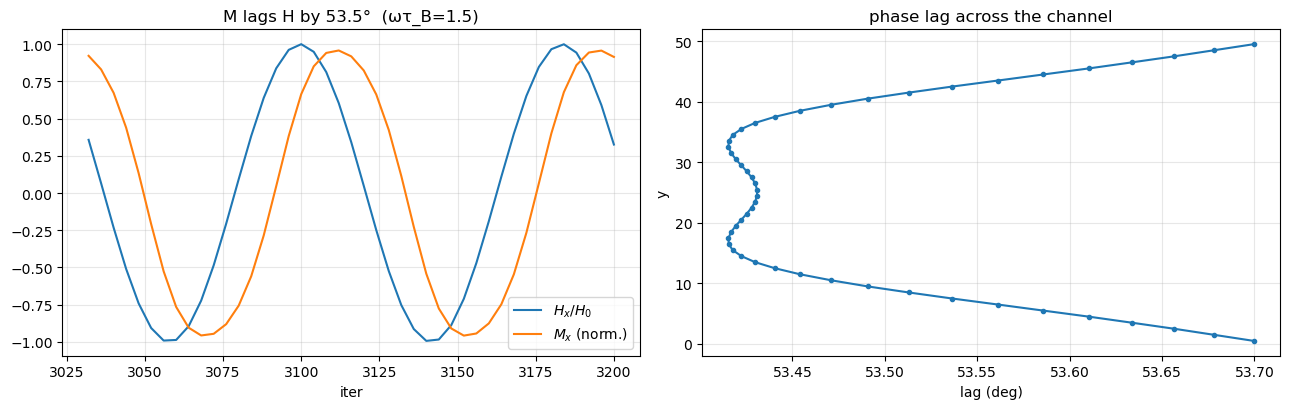

domain-averaged lag = 53.50 deg   (0°→in phase, 90°→max dissipation)


In [8]:
# A1 -- domain-averaged M lag behind the applied field, over the limit cycle.
its, paths = dense_series(DENSE_BASE)
Mx_t = np.array([pd.read_csv(p, skipinitialspace=True).Mx.mean() for p in paths])
My_t = np.array([pd.read_csv(p, skipinitialspace=True).My.mean() for p in paths])
th   = omega * its
Happ = H0x_amp * np.cos(th)

# fit Mx(t) = a cos(wt) + b sin(wt)  ->  lag = atan2(b, a)
A = np.column_stack([np.cos(th), np.sin(th)])
(a, b), *_ = np.linalg.lstsq(A, Mx_t, rcond=None)
lag_deg = np.degrees(np.arctan2(b, a))
amp     = np.hypot(a, b)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(its, Happ/H0x_amp, label=r"$H_x/H_0$")
ax[0].plot(its, Mx_t/amp,     label=r"$M_x$ (norm.)")
ax[0].set(xlabel="iter", title=f"M lags H by {lag_deg:.1f}°  (ωτ_B={WTB})"); ax[0].legend(); ax[0].grid(alpha=.3)
# also show per-y lag: how the lag varies across the channel
nY = pd.read_csv(paths[0], skipinitialspace=True).j.max()+1
Mx_yt = np.array([to_grid(pd.read_csv(p, skipinitialspace=True), "Mx").mean(0) for p in paths])  # (t, y)
lag_y = []
for jj in range(nY):
    (aa, bb), *_ = np.linalg.lstsq(A, Mx_yt[:, jj], rcond=None)
    lag_y.append(np.degrees(np.arctan2(bb, aa)))
ax[1].plot(lag_y, np.arange(nY)+0.5, '-o', ms=3)
ax[1].set(xlabel="lag (deg)", ylabel="y", title="phase lag across the channel"); ax[1].grid(alpha=.3)
fig.tight_layout(); plt.show()
print(f"domain-averaged lag = {lag_deg:.2f} deg   (0°→in phase, 90°→max dissipation)")